In [1]:
import matplotlib.pyplot as plt
import numpy as np
import itertools
import random
import json
import math
import os

In [ ]:
# worsen all-to-all K = 8, timpi in us:

# default_0.0: 113552
# default_0.05: 1275090
# default_0.1: 2203290
# default_0.15: 3126182
# default_0.2: ??? (4049074) -- liniar din 0.1, 0.15.

# -14_0.0: 108300
# -14_0.05: 1148210
# -14_0.1: 1381540
# -14_0.15: 1491759
# -14_0.2: 1625031

# -138_0.0: 108492
# -138_0.05: 1158463
# -138_0.1: 1741143
# -138_0.15: 1905896
# -138_0.2: 2026140

In [8]:
# "/home/vlad/Documents/SublimeMerge/dragonfly-scripts/server_mirror/uet-htsim/htsim/sim/datacenter/dragonfly_plus_experiments/jsons/full_all_to_all_worsen_early_competions_1779143979.json",

json_names = {
    "all_to_all": {
        4: "/home/vlad/Documents/SublimeMerge/dragonfly-scripts/server_mirror/uet-htsim/htsim/sim/datacenter/dragonfly_plus_experiments/jsons/full_all_to_all_worsen_early_competions_1779183975.json",
        6: "/home/vlad/Documents/SublimeMerge/dragonfly-scripts/server_mirror/uet-htsim/htsim/sim/datacenter/dragonfly_plus_experiments/jsons/full_all_to_all_worsen_early_competions_1779204486.json",
        # ! 8 are doar 0.05 si 0.1.
        8: "/home/vlad/Documents/SublimeMerge/dragonfly-scripts/server_mirror/uet-htsim/htsim/sim/datacenter/dragonfly_plus_experiments/jsons/full_all_to_who_worsen_early_competions_1787863975.json",
    },
    "all_to_one": {
        4: "/home/vlad/Documents/SublimeMerge/dragonfly-scripts/server_mirror/uet-htsim/htsim/sim/datacenter/dragonfly_plus_experiments/jsons/full_all_to_who_worsen_early_competions_1779290112.json",
        6: "/home/vlad/Documents/SublimeMerge/dragonfly-scripts/server_mirror/uet-htsim/htsim/sim/datacenter/dragonfly_plus_experiments/jsons/full_all_to_who_worsen_early_competions_1779290350.json",
        8: "/home/vlad/Documents/SublimeMerge/dragonfly-scripts/server_mirror/uet-htsim/htsim/sim/datacenter/dragonfly_plus_experiments/jsons/full_all_to_who_worsen_early_competions_1779292594.json",
    }
}

ht_k_scores = {
    4: [("0", "best"), ("-6", "random"), ("default", "default")],
    6: [("0", "best"), ("-40", "random"), ("default", "default")],
    8: [("-14", "best"), ("-138", "random"), ("default", "default")]
}

all_raps = [0.0, 0.05, 0.1, 0.15, 0.2, 0.3]

In [68]:
def plot_json(fname: str, ax, show_xlabel, show_ylabel, show_legend, add_parsed_logfile_info = False):
    with open(fname) as fin:
        ht = json.load(fin)
    
    k = ht["K"]
    worsen_raps = [0.0] + ht["WORSEN_RAPS"]
    
    oys = {score_name: np.array([ht[f"{score}_{rap_w}"]["mean_fcts"][-1] for rap_w in worsen_raps]) for score, score_name in ht_k_scores[k]}
    
    # adauga info pentru K = 8, all_to_all, worsen 15%/20%. Info scos din parsare logfiles.
    if add_parsed_logfile_info:
        worsen_raps.extend([0.15, 0.2])
        oys["best"] = np.hstack([oys["best"], [1491759.0, 1625031.0]])
        oys["random"] = np.hstack([oys["random"], [1905896.0, 2026140.0]])
        oys["default"] = np.hstack([oys["default"], [3126182.0, 4049074.0]]) # extrapolat pentru 0.2.
    
    # print(f"{oys = }")
    
    for score, score_name in ht_k_scores[k]:
        ax[0].plot(worsen_raps, oys[score_name], ls = "--", marker = 'o')
        
    ax[1].plot(worsen_raps, oys["best"] / oys["default"], ls = "--", marker = 'o')
    ax[1].plot(worsen_raps, oys["random"] / oys["default"], ls = "--", marker = 'o')
    
    if add_parsed_logfile_info:
        kwargs = {"marker": 'D', "s": 100, "alpha": 0.5, "zorder": 3}
        ax[0].scatter([worsen_raps[-1]], [oys["default"][-1]], c = "C2", **kwargs)
        ax[1].scatter([worsen_raps[-1]], [oys["best"][-1] / oys["default"][-1]], c = "C0", **kwargs)
        ax[1].scatter([worsen_raps[-1]], [oys["random"][-1] / oys["default"][-1]], c = "C1", **kwargs)

    for i in range(2):
        ax[i].set_xticks(all_raps)
        if show_legend:
            ax[i].legend([score_name for _, score_name in ht_k_scores[k]])
        if show_xlabel[i]:
            ax[i].set_xlabel("worsen first % finishing flows")

    if show_ylabel[0]:
        ax[0].set_ylabel("mean FCT (us)")
    if show_ylabel[1]:
        ax[1].set_ylabel("mean FCT against\ndefault topology")
    
    fmt = ax[0].yaxis.get_major_formatter()
    fmt.set_scientific(True)
    fmt.set_powerlimits((3, 4))

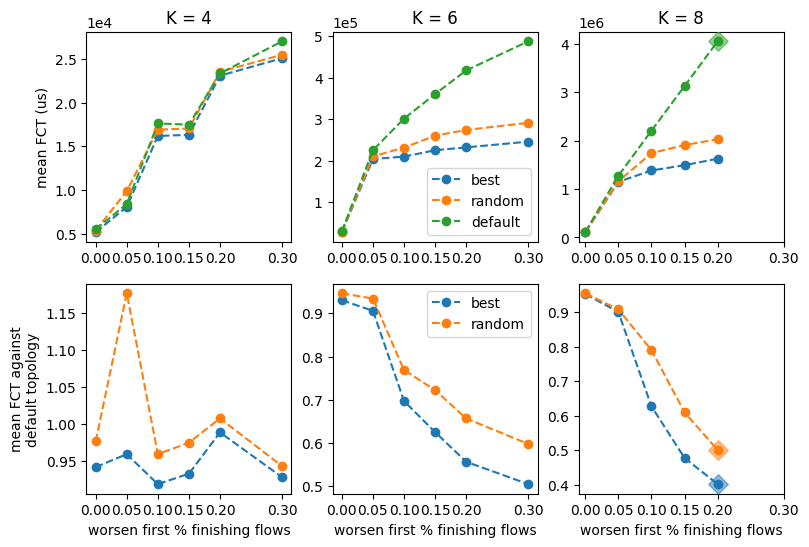

In [70]:
fig, ax = plt.subplots(2, 3, figsize = (9, 6))

plot_json(json_names["all_to_all"][4], [ax[0, 0], ax[1, 0]], show_xlabel = [False, True], show_ylabel = [True, True], show_legend = False)
plot_json(json_names["all_to_all"][6], [ax[0, 1], ax[1, 1]], show_xlabel = [False, True], show_ylabel = [False, False], show_legend = True)
plot_json(json_names["all_to_all"][8], [ax[0, 2], ax[1, 2]], show_xlabel = [False, True], show_ylabel = [False, False], show_legend = False, add_parsed_logfile_info = True)

for i, k in enumerate([4, 6, 8]):
    ax[0, i].set_title(f"K = {k}")

fig.savefig(
    f"/home/vlad/Desktop/Probleme/LaburiDC/figs_implicit_asymmetry/htsim_one_col_fig_all_to_all_worsen_early_completions.pdf",
    bbox_inches = "tight", pad_inches = 1e-2
)

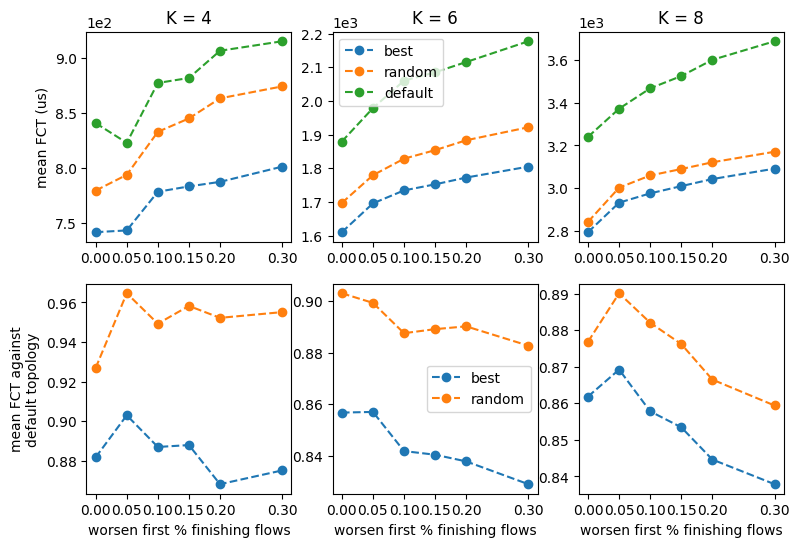

In [72]:
fig, ax = plt.subplots(2, 3, figsize = (9, 6))

plot_json(json_names["all_to_one"][4], [ax[0, 0], ax[1, 0]], show_xlabel = [False, True], show_ylabel = [True, True], show_legend = False)
plot_json(json_names["all_to_one"][6], [ax[0, 1], ax[1, 1]], show_xlabel = [False, True], show_ylabel = [False, False], show_legend = True)
plot_json(json_names["all_to_one"][8], [ax[0, 2], ax[1, 2]], show_xlabel = [False, True], show_ylabel = [False, False], show_legend = False)

for i, k in enumerate([4, 6, 8]):
    ax[0, i].set_title(f"K = {k}")

fig.savefig(
    f"/home/vlad/Desktop/Probleme/LaburiDC/figs_implicit_asymmetry/htsim_one_col_fig_all_to_one_worsen_early_completions.pdf",
    bbox_inches = "tight", pad_inches = 1e-2
)

oys = {'best': array([ 5163.51 ,  8052.866, 16192.24 , 16317.64 , 23102.74 , 25101.26 ]), 'random': array([ 5353.43 ,  9877.118, 16909.22 , 17049.   , 23543.78 , 25506.04 ]), 'default': array([ 5481.64,  8393.15, 17621.5 , 17488.5 , 23363.5 , 27043.7 ])}


Text(0.5, 0.98, 'K = 4')

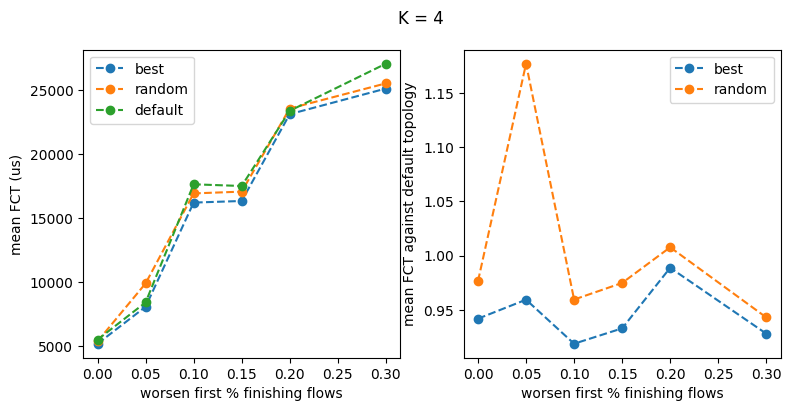

In [67]:
fig, ax = plt.subplots(1, 2, figsize = (9, 4))

k = 4
plot_json(json_names["all_to_all"][k], ax)
fig.suptitle(f"K = {k}")

oys = {'best': array([ 28120.46666667, 204276.66666667, 210128.        , 225422.66666667,
       232335.        , 246124.66666667]), 'random': array([ 28607.1       , 210686.        , 231743.66666667, 260468.        ,
       274204.66666667, 291510.        ]), 'default': array([ 30229.1, 225562. , 301509. , 360688. , 417609. , 487832. ])}


Text(0.5, 0.98, 'K = 6')

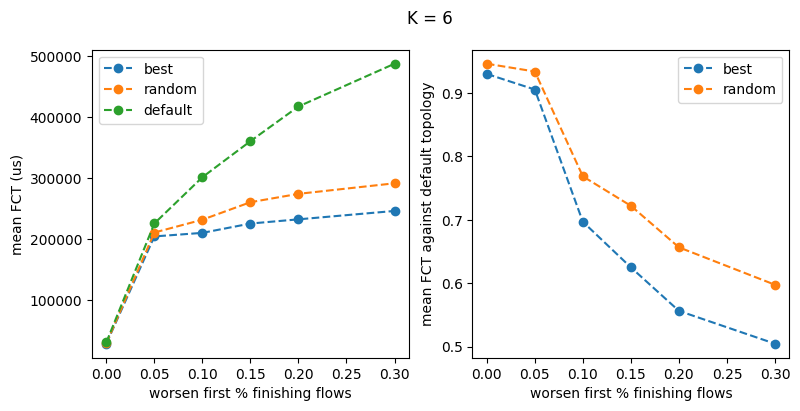

In [68]:
fig, ax = plt.subplots(1, 2, figsize = (9, 4))

k = 6
plot_json(json_names["all_to_all"][k], ax)
fig.suptitle(f"K = {k}")

oys = {'best': array([741.43848 , 743.041208, 778.259032, 783.121848, 787.250704,
       801.107584]), 'random': array([779.3354  , 793.671896, 832.811632, 845.003864, 863.301032,
       874.181408]), 'default': array([840.7432 , 822.7922 , 877.31676, 881.84396, 906.62756, 915.27276])}


Text(0.5, 0.98, 'K = 4')

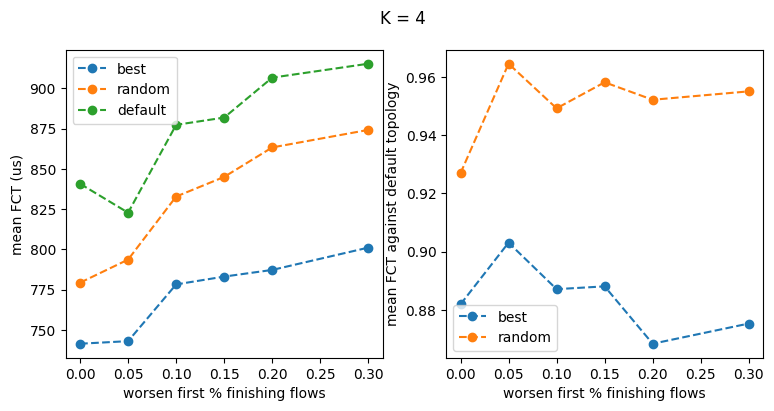

In [73]:
fig, ax = plt.subplots(1, 2, figsize = (9, 4))

k = 4
plot_json(json_names["all_to_one"][k], ax)
fig.suptitle(f"K = {k}")

oys = {'best': array([1610.3376 , 1695.85964, 1734.40252, 1752.4226 , 1772.54868,
       1805.00624]), 'random': array([1697.2768 , 1779.5108 , 1828.56276, 1853.94008, 1883.3114 ,
       1921.91764]), 'default': array([1879.582 , 1978.8146, 2060.2784, 2085.1892, 2115.6486, 2177.3346])}


Text(0.5, 0.98, 'K = 6')

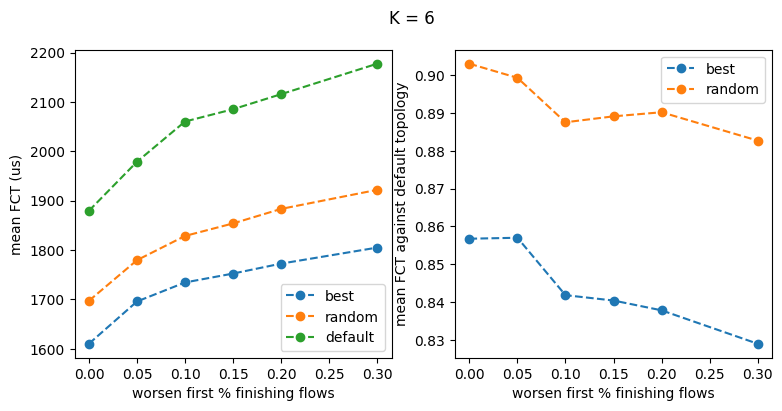

In [74]:
fig, ax = plt.subplots(1, 2, figsize = (9, 4))

k = 6
plot_json(json_names["all_to_one"][k], ax)
fig.suptitle(f"K = {k}")

oys = {'best': array([2792.762     , 2931.38364706, 2974.99070588, 3008.98541176,
       3042.16705882, 3090.97541176]), 'random': array([2841.3048    , 3001.77176471, 3059.01181176, 3089.23736471,
       3120.93456471, 3170.36515294]), 'default': array([3240.438     , 3372.45635294, 3468.18423529, 3525.76623529,
       3601.87305882, 3689.07458824])}


Text(0.5, 0.98, 'K = 8')

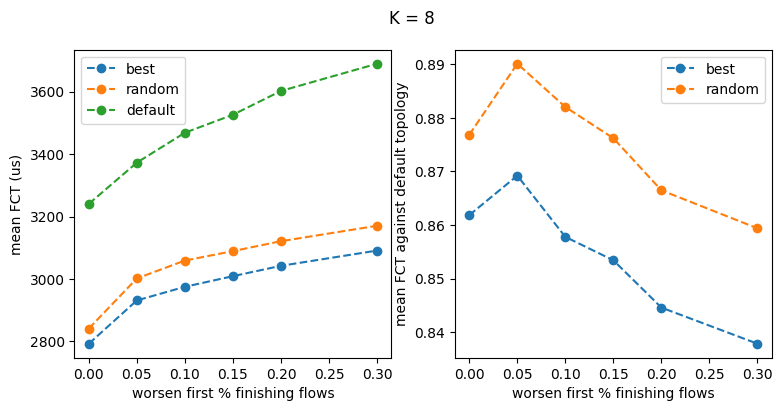

In [76]:
fig, ax = plt.subplots(1, 2, figsize = (9, 4))

k = 8
plot_json(json_names["all_to_one"][k], ax)
fig.suptitle(f"K = {k}")